In [27]:
import arxiv
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import ArxivAPIWrapper,WikipediaAPIWrapper
from langchain_tavily import TavilySearch
from langchain_groq import ChatGroq
from dotenv import load_dotenv

In [28]:
llm=ChatGroq(model="qwen/qwen3.8-27b")

In [ ]:
load_dotenv

In [ ]:
arxiv.Client.query_url_format = "https://export.arxiv.org/api/query?{}"

In [ ]:
api_wrapper_arvix=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arvix=ArxivQueryRun(api_wrapper=api_wrapper_arvix,description='Query arvix papers')
print(arvix.name)

In [ ]:
arvix.invoke("attention is all you need")

In [ ]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)

In [ ]:
wiki.invoke("what is AI")

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()

print("API key loaded:", bool(os.getenv("TAVILY_API_KEY")))

In [ ]:
tavily = TavilySearch(
    max_results=2,tavily_api_key=os.environ["TAVILY_API_KEY"]
)

In [ ]:
tavily.invoke("what is lastest AI virsl news")

In [29]:
tools=[arvix,wiki,tavily]

In [30]:
llm_tools=llm.bind_tools(tools=tools)

In [31]:
llm_tools.invoke("what is the recent news on AI")

AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'q6bb2ywhg', 'function': {'arguments': '{"query":"latest AI news 2025","search_depth":"advanced","time_range":"month","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 76, 'prompt_tokens': 1994, 'total_tokens': 2070, 'completion_time': 0.189403095, 'completion_tokens_details': None, 'prompt_time': 0.141803035, 'prompt_tokens_details': None, 'queue_time': 0.124629523, 'total_time': 0.33120613}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e77f-f6bc-7023-afce-f5041b71f8f6-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'latest AI news 2025', 'search_depth': 'advanced', 'time_range': 'month', 'topic': 'news'}, 'id': 'q6bb2ywhg', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_

In [34]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages

In [35]:
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

In [36]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition


In [37]:
def tool_calling_llm(state:State):
    return {"messages":llm_tools.invoke(state["messages"])}

In [50]:
builder_v1=StateGraph(State)
builder_v1.add_node("tool_calling_llm",tool_calling_llm)
builder_v1.add_node('tools',ToolNode(tools))

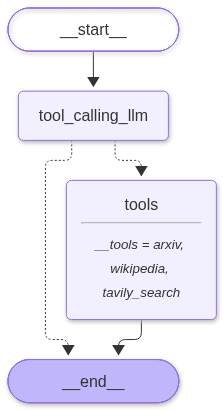

In [51]:
builder_v1.add_edge(START,"tool_calling_llm")
builder_v1.add_conditional_edges("tool_calling_llm",tools_condition)
builder_v1.add_edge("tools",END)

graph_complie=builder_v1.compile()

display(Image(graph_complie.get_graph().draw_mermaid_png()))

In [53]:
results=graph_complie.invoke({"messages":"What is AI Engineering?"})
for r in results['messages']:
    r.pretty_print()


================================ Human Message =================================

What is AI Engineering?
================================== Ai Message ==================================

I'll look up the latest information on AI Engineering to give you an accurate, well-grounded answer.
Tool Calls:
  tavily_search (d8sbnz11k)
 Call ID: d8sbnz11k
  Args:
    query: What is AI Engineering definition 2024 2025
    search_depth: None
  wikipedia (jff3gdbfa)
 Call ID: jff3gdbfa
  Args:
    query: AI Engineering
================================= Tool Message =================================
Name: tavily_search

{"query": "What is AI Engineering definition 2024 2025", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.thehackettgroup.com/glossary/ai-engineering", "title": "Definition of AI Engineering - The Hackett Group® Glossary", "content": "AI engineering is the discipline of developing, designing and implementing artificial intelligence (AI) sys

V2

In [62]:
builder_v2=StateGraph(State)
builder_v2.add_node("tool_calling_llm",tool_calling_llm)
builder_v2.add_node('tools',ToolNode(tools))

In [63]:
builder_v2.add_edge(START,"tool_calling_llm")
builder_v2.add_conditional_edges("tool_calling_llm",tools_condition)
builder_v2.add_edge("tools","tool_calling_llm")

graph_complie_v2=builder_v2.compile()

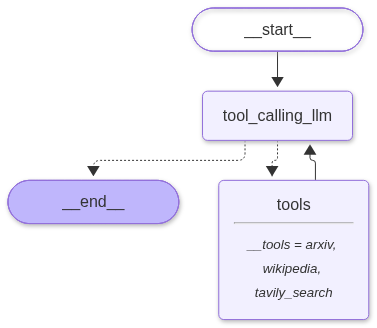

In [64]:
flow=display(Image(graph_complie_v2.get_graph().draw_mermaid_png()))

In [65]:
results=graph_complie_v2.invoke({"messages":"What is AI Engineering?then get me recent research paper on quantum computing"})
for r in results['messages']:
    r.pretty_print()

================================ Human Message =================================

What is AI Engineering?then get me recent research paper on quantum computing
================================== Ai Message ==================================

## What is AI Engineering?

**AI Engineering** is the discipline of designing, building, deploying, and maintaining artificial intelligence systems in real-world production environments. It sits at the intersection of software engineering, data engineering, and machine learning. Key aspects include:

- **Building and deploying ML/AI models** into scalable, reliable systems (not just academic prototypes)
- **Data pipelines** – ingesting, cleaning, and managing data at scale
- **Model evaluation and monitoring** – tracking performance, drift, and reliability in production
- **MLOps/LLMOps** – continuous integration/continuous deployment (CI/CD) practices tailored for AI systems
- **Integration** – embedding AI capabilities into products, APIs, and us